## Bussiness Problem : 

* Group nearby delivery locations into clusters so that a delivery company can organize its deliveries more efficiently.
* Suppose an e-commerce company receives 12 delivery orders across a city. The delivery locations are scattered across different areas.
* Instead of assigning all 12 orders randomly to delivery staff, we can use a clustering algorithm to group nearby locations.

In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv(r"D:\Delivery_Location_Clustering\data\delivery_locations_800.csv")
df.head()

,Delivery_ID,Latitude,Longitude
0,D0001,20.288922,85.824275
1,D0002,20.292178,85.836406
2,D0003,20.298035,85.826724
3,D0004,20.290718,85.820873
4,D0005,20.296763,85.824665


In [3]:
df.shape

(800, 3)

In [4]:
df.columns.tolist()

['Delivery_ID', 'Latitude', 'Longitude']

* Delivery_ID : It is a unique identifier assigned to each delivery.
* Latitude : Latitude represents the north–south position of a location on Earth.It ranges from -90 to +90 degrees.Positive values represent locations north of the Equator, while negative values represent locations south of it.
* Longitude : Longitude represents the east–west position of a location on Earth.It ranges from -180 to +180 degrees.Positive values generally represent locations east of the Prime Meridian, while negative values represent locations west of it.

In [5]:
df.dtypes

Delivery_ID        str
Latitude       float64
Longitude      float64
dtype: object

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Delivery_ID  800 non-null    str    
 1   Latitude     800 non-null    float64
 2   Longitude    800 non-null    float64
dtypes: float64(2), str(1)
memory usage: 18.9 KB


In [7]:
df.isna().sum()

Delivery_ID    0
Latitude       0
Longitude      0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
for col in df.columns.tolist():
    print(col)
    print(df[col].nunique())
    print("\n")

Delivery_ID
800


Latitude
794


Longitude
798




In [10]:
df[['Latitude','Longitude']].duplicated().sum()

np.int64(0)

In [11]:
x = df[['Latitude','Longitude']]

In [12]:
x.shape

(800, 2)

In [13]:
invalid_coordinates =x[(
    ~x["Latitude"].between(-90, 90)
    | ~x["Longitude"].between(-180, 180)
)]

In [14]:
invalid_coordinates

,Latitude,Longitude


In [15]:
import matplotlib.pyplot as plt

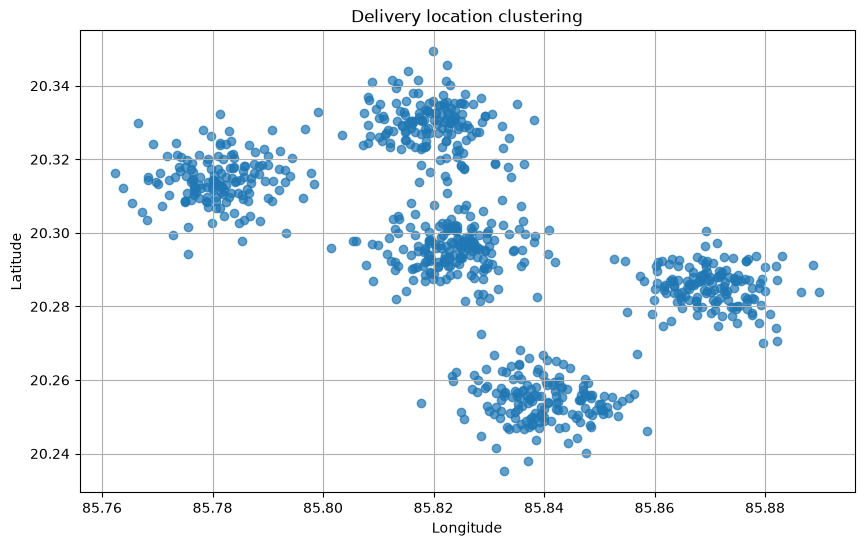

In [16]:
plt.figure(figsize=(10,6))
plt.scatter(x['Longitude'],x['Latitude'],alpha=0.7)
plt.title("Delivery location clustering")
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.grid(True)
plt.show()

In [17]:
from sklearn.cluster import KMeans

In [22]:
wcss = []
for rr in range(1,min(11,len(x))):
    kmean = KMeans(n_clusters=rr,init='k-means++',random_state=42)
    kmean.fit(x)
    wcss.append(kmean.inertia_)

wcss

[1.2226249208557505,
 0.479153006971749,
 0.3120310704322767,
 0.16546738484655968,
 0.06845529504403572,
 0.06295586235025809,
 0.05691460426987457,
 0.05314822975319605,
 0.047646744729909,
 0.0449054154634872]

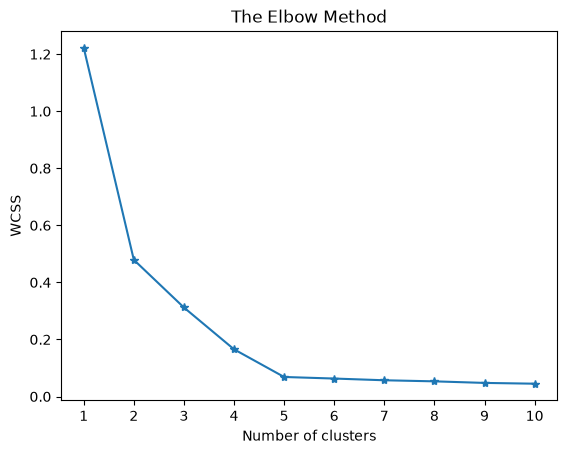

In [24]:
plt.plot(range(1, min(11,len(x))), wcss, marker="*")
plt.xticks(range(1, min(11,len(x))))
plt.title('The Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')
plt.show()

In [25]:
kmean = KMeans(n_clusters=5,init='k-means++',random_state=True)
df['Cluster'] = kmean.fit_predict(x)
df

,Delivery_ID,Latitude,Longitude,Cluster
0,D0001,20.288922,85.824275,2
1,D0002,20.292178,85.836406,2
2,D0003,20.298035,85.826724,2
3,D0004,20.290718,85.820873,2
4,D0005,20.296763,85.824665,2
...,...,...,...,...
795,D0796,20.314829,85.786930,3
796,D0797,20.313125,85.777521,3
797,D0798,20.313924,85.780638,3
798,D0799,20.313856,85.779117,3


In [26]:
df['Cluster'].unique()

array([2, 1, 0, 4, 3], dtype=int32)

In [27]:
kmean.labels_

array([2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,

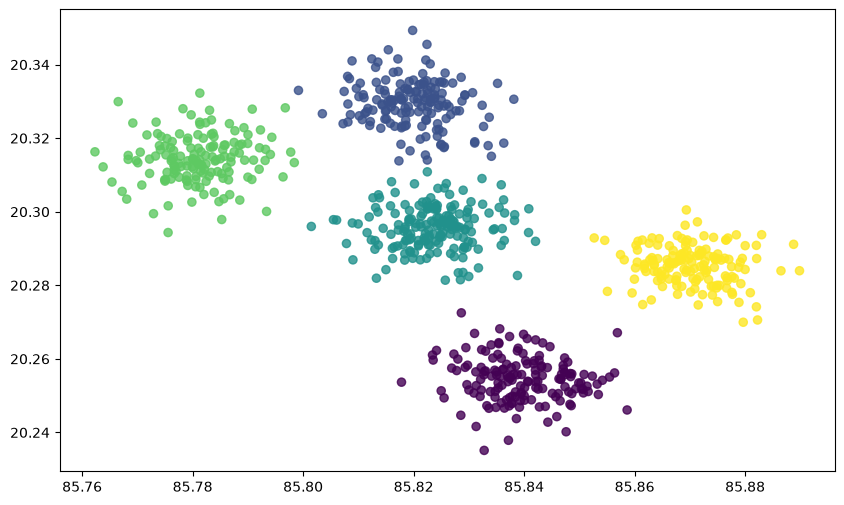

In [32]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["Longitude"],
    df["Latitude"],
    c=df["Cluster"],
    cmap="viridis",
    s=35,
    alpha=0.8
)

In [34]:
kmean.cluster_centers_

array([[20.25449379, 85.83955951],
       [20.32939032, 85.81981681],
       [20.29560216, 85.82356382],
       [20.31429141, 85.78112995],
       [20.28538817, 85.87035038]])

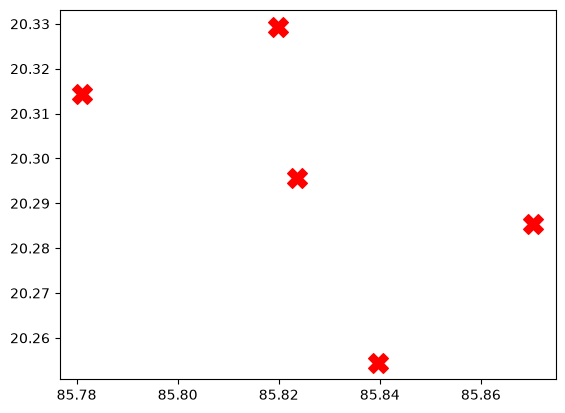

In [33]:
centers = kmean.cluster_centers_

plt.scatter(
    centers[:, 1],
    centers[:, 0],
    marker="X",
    s=200,
    color="red",
    label="Cluster Centers"
)

In [35]:
from sklearn.metrics import silhouette_score

silhouette_avg = silhouette_score(x, df["Cluster"])

print("Number of clusters:", kmean.n_clusters)
print("Silhouette Score:", round(silhouette_avg, 4))

Number of clusters: 5
Silhouette Score: 0.6898


In [37]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

silhouette_scores = {}

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(x)

    score = silhouette_score(x, labels)
    silhouette_scores[k] = score

for k, score in silhouette_scores.items():
    print(f"K = {k}, Silhouette Score = {score:.4f}")

K = 2, Silhouette Score = 0.5259
K = 3, Silhouette Score = 0.5235
K = 4, Silhouette Score = 0.6019
K = 5, Silhouette Score = 0.6898
K = 6, Silhouette Score = 0.6166
K = 7, Silhouette Score = 0.5377
K = 8, Silhouette Score = 0.4652
K = 9, Silhouette Score = 0.4043
K = 10, Silhouette Score = 0.3387


In [38]:
best_k = max(silhouette_scores, key=silhouette_scores.get)

print("Best K based on Silhouette Score:", best_k)
print(
    "Best Silhouette Score:",
    round(silhouette_scores[best_k], 4)
)

Best K based on Silhouette Score: 5
Best Silhouette Score: 0.6898


In [40]:
from sklearn.cluster import KMeans

best_kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

df["Cluster"] = best_kmeans.fit_predict(x)

print("Final model trained successfully!")
print("Selected number of clusters:", best_k)

Final model trained successfully!
Selected number of clusters: 5


In [41]:
df

,Delivery_ID,Latitude,Longitude,Cluster
0,D0001,20.288922,85.824275,2
1,D0002,20.292178,85.836406,2
2,D0003,20.298035,85.826724,2
3,D0004,20.290718,85.820873,2
4,D0005,20.296763,85.824665,2
...,...,...,...,...
795,D0796,20.314829,85.786930,1
796,D0797,20.313125,85.777521,1
797,D0798,20.313924,85.780638,1
798,D0799,20.313856,85.779117,1
